# PM2.5 Regression + Kriging (Standard Layers)

This notebook mirrors the temperature workflow and models **PM2.5** using the standard layers in `README.md`: NDVI, impervious surface, road density, emissions (NEI), and population density.

In [31]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

In [32]:
# Load extracted PM2.5 layers
LAYER_DIR = DATA_DIR / "kriging_satellite" / "layers"

required_layer_paths = {
    "ndvi": LAYER_DIR / "ndvi_grid.geojson",
    "impervious": LAYER_DIR / "nlcd_impervious_grid.geojson",
    "road_density": LAYER_DIR / "road_density_grid.geojson",
    "emissions": LAYER_DIR / "nei_emissions_grid.geojson",
    "population_density": LAYER_DIR / "population_density_grid.geojson",
}

missing_required = [name for name, path in required_layer_paths.items() if not path.exists()]
if missing_required:
    raise FileNotFoundError(f"Missing required PM2.5 layers: {missing_required}")

layer_gdfs = {name: gpd.read_file(path) for name, path in required_layer_paths.items()}
print("Loaded required layers:", list(required_layer_paths.keys()))

In [33]:
# Load Boston sensor series and compute mean PM2.5 between 15:00 and 16:00
SENSORS_DIR = DATA_DIR / "sensors"
sensor_csvs = {
    "Boston Carter Field": SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall": SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B": SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way": SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

missing_csvs = [name for name, path in sensor_csvs.items() if not path.exists()]
if missing_csvs:
    raise FileNotFoundError(f"Missing sensor CSV files for: {missing_csvs}")

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}

aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="pm25",
    time_column="timestamp",
    sampling_interval="1min",
    timestamp_tolerance="15min",
)

initial_time = "15:00"
final_time = "16:00"
aligned_between = aligned_df.between_time(initial_time, final_time)
if aligned_between.empty:
    raise ValueError("No aligned PM2.5 data between 15:00 and 16:00.")

measurements_at_timestamp = aligned_between.mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
sensor_names = list(sensor_csvs.keys())

sensor_pm25 = measurements_at_timestamp.reindex(sensor_names)
if sensor_pm25.isna().any():
    missing = sensor_pm25[sensor_pm25.isna()].index.tolist()
    raise ValueError(f"Missing PM2.5 values for sensors: {missing}")

sensor_locations = sensor_locations[sensor_locations["sensor_name"].isin(sensor_names)].copy()
sensor_locations = sensor_locations.set_index("sensor_name").loc[sensor_names].reset_index()
sensor_locations["pm25"] = sensor_pm25.values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations["longitude"], sensor_locations["latitude"]),
    crs="EPSG:4326",
)

print(f"Aligned rows total: {len(aligned_df)}")
print(f"Aligned rows between {initial_time} and {final_time}: {len(aligned_between)}")
gdf_sensors[["sensor_name", "pm25", "geometry"]]

In [34]:
# Merge layer predictors onto one grid and map sensors to cells
def _ensure_grid_id(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    if "grid_id" in gdf.columns:
        return gdf.copy()
    if "id" in gdf.columns:
        out = gdf.copy()
        out = out.rename(columns={"id": "grid_id"})
        return out
    return gdf.reset_index(drop=False).rename(columns={"index": "grid_id"})


def _pick_feature_col(gdf: gpd.GeoDataFrame, candidates: list[str], feature_name: str) -> str:
    for col in candidates:
        if col in gdf.columns:
            return col
    raise ValueError(
        f"No usable column found for '{feature_name}'. Tried {candidates}. "
        f"Available columns: {list(gdf.columns)}"
    )


base = _ensure_grid_id(layer_gdfs["ndvi"])
base_crs = base.crs

feature_specs = [
    ("ndvi", ["ndvi", "ndvi_mean", "ndvi_median"], "ndvi"),
    ("impervious", ["impervious", "nlcd_impervious", "impervious_surface"], "impervious"),
    ("road_density", ["road_density_km_km2", "major_road_density_km_km2", "road_density"], "road_density"),
    ("emissions", ["emissions_tpy", "total_emissions_tpy", "emissions", "emissions_point_tpy"], "emissions"),
    ("population_density", ["population_density_km2_clipped", "population_density_km2", "population_density", "population"], "population_density"),
]

grid_features = base[["grid_id", "geometry"]].copy()
predictor_cols = []

for layer_name, candidates, out_name in feature_specs:
    layer = _ensure_grid_id(layer_gdfs[layer_name])
    if layer.crs != base_crs:
        layer = layer.to_crs(base_crs)
    selected_col = _pick_feature_col(layer, candidates, out_name)
    predictor_cols.append(out_name)
    grid_features = grid_features.merge(
        layer[["grid_id", selected_col]].rename(columns={selected_col: out_name}),
        on="grid_id",
        how="left",
    )

sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(
    sensors_proj,
    grid_features,
    how="left",
    predicate="within",
)

# Fallback for unmatched points: nearest grid cell
unmatched_mask = sensor_with_grid["grid_id"].isna()
if unmatched_mask.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched_mask].copy(),
        grid_features,
        how="left",
        distance_col="distance_to_grid",
    )
    fill_cols = ["grid_id"] + predictor_cols
    sensor_with_grid.loc[unmatched_mask, fill_cols] = nearest[fill_cols].to_numpy()

# Domain-safe fill: no road/emission feature in a cell means 0, not nearest hotspot
zero_fill_cols = ["road_density", "emissions"]
for col in zero_fill_cols:
    sensor_with_grid[col] = sensor_with_grid[col].fillna(0.0)
    grid_features[col] = grid_features[col].fillna(0.0)

# For the remaining predictors, use nearest valid cell fallback for sensors
for col in predictor_cols:
    if col in zero_fill_cols:
        continue
    nan_mask = sensor_with_grid[col].isna()
    if not nan_mask.any():
        continue

    valid_cells = grid_features[["geometry", col]].dropna(subset=[col]).copy()
    if valid_cells.empty:
        continue

    nearest_valid = gpd.sjoin_nearest(
        sensors_proj.loc[nan_mask].copy(),
        valid_cells,
        how="left",
        distance_col=f"distance_to_{col}",
    )
    sensor_with_grid.loc[nan_mask, col] = nearest_valid[col].to_numpy()

# Final grid NaN fill for any remaining holes
for col in predictor_cols:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

sensor_cell_df = pd.DataFrame(
    {
        "sensor_name": sensor_with_grid["sensor_name"],
        "pm25": sensor_with_grid["pm25"],
        "grid_id": sensor_with_grid["grid_id"],
        **{c: sensor_with_grid[c] for c in predictor_cols},
    }
).drop_duplicates(subset=["sensor_name"]).reset_index(drop=True)

print("Predictors used:", predictor_cols)
sensor_cell_df

Predictors used: ['ndvi', 'impervious', 'road_density', 'emissions', 'population_density']


,sensor_name,pm25,grid_id,ndvi,impervious,road_density,emissions,population_density
0,Boston Carter Field,10.322884,678,0.035911,86.844909,30.825609,0.0,15416.359799
1,Boston Gainsborough Parking Garage,16.439812,288,0.349933,32.767644,7.020464,0.0,382.572783
2,Boston Robinson Hall,0.003135,615,0.184991,81.500348,23.648700,0.0,14069.321505
3,Boston West Village B,0.884483,401,0.233308,84.536850,0.000000,0.0,14068.100841
4,Boston World Series Way,23.751881,494,0.130808,86.319335,22.433620,0.0,14068.100841


In [35]:
# Feature engineering + ridge train (log target + scaled predictors)
for frame in [sensor_cell_df, grid_features]:
    frame["road_density_log1p"] = np.log1p(frame["road_density"].clip(lower=0.0))
    frame["emissions_log1p"] = np.log1p(frame["emissions"].clip(lower=0.0))
    frame["population_density_log1p"] = np.log1p(frame["population_density"].clip(lower=0.0))

predictor_cols_model = [
    "ndvi",
    "impervious",
    "road_density_log1p",
    "emissions_log1p",
    "population_density_log1p",
]

target_col = "pm25"
train_df = sensor_cell_df[[target_col] + predictor_cols_model].dropna().copy()
if train_df.empty:
    raise ValueError("No sensor rows available for training after dropping NaNs.")

train_df["pm25_log1p"] = np.log1p(train_df[target_col].clip(lower=0.0))

# Scale predictors using training stats (prevents domination by large-magnitude features)
feature_mean = train_df[predictor_cols_model].mean()
feature_std = train_df[predictor_cols_model].std(ddof=0).replace(0, 1.0)
X_train_scaled = (train_df[predictor_cols_model] - feature_mean) / feature_std

ridge_model = train_ridge(
    X=X_train_scaled,
    y=train_df["pm25_log1p"],
    alpha=1.0,
    fit_intercept=True,
)

print("Ridge model trained (log1p PM2.5 target + scaled predictors)")
print("n_samples:", ridge_model["n_samples"])
print("n_features:", ridge_model["n_features"])
print("score_r2:", ridge_model["score_r2"])
for name, coef in zip(predictor_cols_model, ridge_model["coefficients"]):
    print(f"  {name}: {coef:.6f}")
print("intercept:", ridge_model["intercept"])

Ridge model trained (log1p PM2.5 target + scaled predictors)
n_samples: 5
n_features: 5
score_r2: 0.4370889259794478
  ndvi: -0.566583
  impervious: -0.251157
  road_density_log1p: 0.188658
  emissions_log1p: 0.000000
  population_density_log1p: -0.606281
intercept: 1.8262532374263283


Ridge PM2.5 stats: 0.20380019594173476 39.07257264133803 5.636136692102632


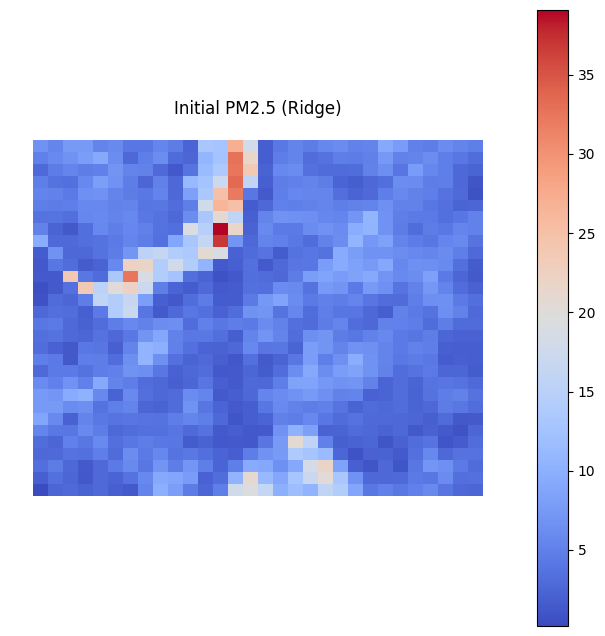

,grid_id,geometry,ndvi,impervious,road_density,emissions,population_density,road_density_log1p,emissions_log1p,population_density_log1p,predicted_log_pm25_ridge,predicted_pm25_ridge
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637,59.043725,0.000000,0.0,39353.245195,0.000000,0.0,10.580359,0.185483,0.203800
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034,74.126761,24.844960,0.0,39353.245195,3.252116,0.0,10.580359,1.071704,1.920351
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051,76.528328,37.069438,0.0,33870.886499,3.639412,0.0,10.430341,1.471332,3.355030
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749,77.903810,14.902990,0.0,37004.413783,2.766507,0.0,10.518819,1.307107,2.695467
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992,79.078385,17.275134,0.0,39353.245195,2.905541,0.0,10.580359,1.438136,3.212835


In [36]:
# Predict ridge PM2.5 across all grid cells
X_grid_scaled = (grid_features[predictor_cols_model] - feature_mean) / feature_std
grid_features["predicted_log_pm25_ridge"] = ridge_predict(ridge_model, X_grid_scaled.to_numpy(dtype=float))
grid_features["predicted_pm25_ridge"] = np.expm1(grid_features["predicted_log_pm25_ridge"]).clip(lower=0.0)

initial_pm25_map = gpd.GeoDataFrame(grid_features, geometry="geometry", crs=base_crs)

print(
    "Ridge PM2.5 stats:",
    float(initial_pm25_map["predicted_pm25_ridge"].min()),
    float(initial_pm25_map["predicted_pm25_ridge"].max()),
    float(initial_pm25_map["predicted_pm25_ridge"].mean()),
)

fig, ax = plt.subplots(figsize=(8, 8))
initial_pm25_map.plot(column="predicted_pm25_ridge", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Initial PM2.5 (Ridge)")
plt.show()

initial_pm25_map.head()

In [37]:
# Compute sensor residuals in log-space
sensor_model_df = sensor_cell_df[["sensor_name", "pm25"] + predictor_cols_model].dropna().copy()
if sensor_model_df.empty:
    raise ValueError("No sensor rows available for residual computation.")

X_sensor_scaled = (sensor_model_df[predictor_cols_model] - feature_mean) / feature_std
sensor_model_df["ridge_pred_log_at_sensor"] = ridge_predict(
    ridge_model,
    X_sensor_scaled.to_numpy(dtype=float),
)
sensor_model_df["observed_log_pm25"] = np.log1p(sensor_model_df["pm25"].clip(lower=0.0))
sensor_model_df["residual"] = sensor_model_df["observed_log_pm25"] - sensor_model_df["ridge_pred_log_at_sensor"]

sensors_proj = gdf_sensors.to_crs(initial_pm25_map.crs).copy()
sensors_proj["x"] = sensors_proj.geometry.x
sensors_proj["y"] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[["sensor_name", "x", "y"]],
    on="sensor_name",
    how="left",
)

sensor_residuals_df

,sensor_name,pm25,ndvi,impervious,road_density_log1p,emissions_log1p,population_density_log1p,ridge_pred_log_at_sensor,observed_log_pm25,residual,x,y
0,Boston Carter Field,10.322884,0.035911,86.844909,3.460271,0.0,9.643249,2.322517,2.426826,0.104309,234190.269623,898963.472983
1,Boston Gainsborough Parking Garage,16.439812,0.349933,32.767644,2.081996,0.0,5.949529,2.612017,2.858756,0.246739,233362.526656,898959.495289
2,Boston Robinson Hall,0.003135,0.184991,81.500348,3.204724,0.0,9.551823,1.579620,0.003130,-1.576490,234068.072350,898830.485129
3,Boston West Village B,0.884483,0.233308,84.536850,0.000000,0.0,9.551736,0.809265,0.633653,-0.175612,233590.883940,898658.685258
4,Boston World Series Way,23.751881,0.130808,86.319335,3.154172,0.0,9.551736,1.807847,3.208901,1.401054,233808.705971,898786.682334


Residual variogram model:
{'model': 'spherical', 'nugget': 0.7094781825198555, 'sill': 0.2837912730079422, 'range': 82.77525240268393, 'score_mse': 0.9015986631649123, 'lag_centers': [155.20359825503238, 258.6726637583873, 362.14172926174217, 465.6107947650971, 672.5489257718069, 776.0179912751619], 'experimental_semivariance': [1.4125431761535248, 2.837912730079422, 0.08919020064869107, 0.8294089726666082, 0.8506304142118771, 0.010143185519816349], 'fitted_semivariance': [0.9932694555277977, 0.9932694555277977, 0.9932694555277977, 0.9932694555277977, 0.9932694555277977, 0.9932694555277977]}


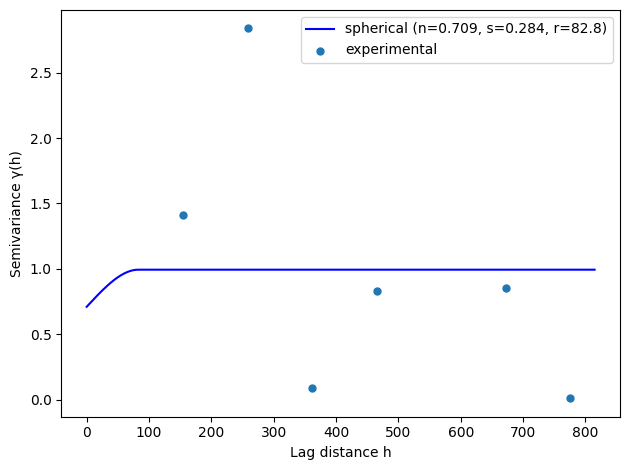

In [38]:
# Fit variogram model on residuals
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(
    points=res_points,
    values=res_values,
)

print("Residual variogram model:")
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

In [39]:
# Krige log-space residuals and produce final PM2.5 map
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_pm25_map.geometry]
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

final_pm25_map = initial_pm25_map.copy()
final_pm25_map["estimated_residual_log"] = estimated_residuals
final_pm25_map["final_log_pm25"] = (
    final_pm25_map["predicted_log_pm25_ridge"] + final_pm25_map["estimated_residual_log"]
)
final_pm25_map["final_pm25_raw"] = np.expm1(final_pm25_map["final_log_pm25"])
final_pm25_map["final_pm25"] = final_pm25_map["final_pm25_raw"].clip(lower=0.0)

print(
    "Final PM2.5 stats:",
    float(final_pm25_map["final_pm25"].min()),
    float(final_pm25_map["final_pm25"].max()),
    float(final_pm25_map["final_pm25"].mean()),
)

PM25_INITIAL_FIG_PATH = LAYER_DIR / "pm25_ridge_initial_map.png"
PM25_FINAL_FIG_PATH = LAYER_DIR / "pm25_ridge_final_map.png"
PM25_INITIAL_FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
PM25_CMAP = "coolwarm"
pm25_min = float(min(initial_pm25_map["predicted_pm25_ridge"].min(), final_pm25_map["final_pm25"].min()))
pm25_max = float(max(initial_pm25_map["predicted_pm25_ridge"].max(), final_pm25_map["final_pm25"].max()))
print(f"Shared PM2.5 color scale: [{pm25_min:.3f}, {pm25_max:.3f}]")

fig_initial, ax_initial = plt.subplots(figsize=(8, 6))
initial_pm25_map.plot(
    column="predicted_pm25_ridge",
    cmap=PM25_CMAP,
    legend=True,
    vmin=pm25_min,
    vmax=pm25_max,
    ax=ax_initial,
)
ax_initial.set_axis_off()
ax_initial.set_title("Initial PM2.5 (Ridge)")
fig_initial.savefig(PM25_INITIAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

fig_final, ax_final = plt.subplots(figsize=(8, 6))
final_pm25_map.plot(
    column="final_pm25",
    cmap=PM25_CMAP,
    legend=True,
    vmin=pm25_min,
    vmax=pm25_max,
    ax=ax_final,
)
ax_final.set_axis_off()
ax_final.set_title("Final PM2.5 (Ridge + Kriged Residual)")
fig_final.savefig(PM25_FINAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved initial PM2.5 figure to: {PM25_INITIAL_FIG_PATH}")
print(f"Saved final PM2.5 figure to: {PM25_FINAL_FIG_PATH}")

final_pm25_map.head()

In [40]:
# Save final output
PM25_OUTPUT_PATH = LAYER_DIR / "pm25_ridge_kriging_grid.geojson"
PM25_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_pm25_map.to_file(PM25_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved final PM2.5 map to: {PM25_OUTPUT_PATH}")